# TinyStories × Masked Diffusion Language Model (MDLM)
### HW2 Problem 2 | Student TODO Notebook (25% Implementation)



## 1. GPU setting

In [ ]:
%pip -q install "datasets>=3.0,<5" "tokenizers>=0.20,<1"

import torch
assert torch.cuda.is_available(), "請先在 Colab 啟用 GPU (Runtime → Change runtime type → T4)"
print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)

GPU: Tesla T4
PyTorch: 2.11.0+cu130


## 2. Imports



In [ ]:

import math
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from datasets import load_dataset
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Device
assert torch.cuda.is_available(), "CUDA GPU not found!"
DEVICE = torch.device("cuda")

# Dataset
TRAIN_STORIES = 120_000
VALID_STORIES = 1_000
TOKENIZER_TRAIN_STORIES = 20_000

# Model / Training configuration
VOCAB_TARGET = 8_000
SEQ_LEN = 128
BATCH_SIZE = 64

# Local output paths
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_PATH = OUTPUT_DIR / "tiny_mdlm_v2.pt"
TOKENIZER_PATH = OUTPUT_DIR / "tiny_mdlm_v2_tokenizer.json"

print("Device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0))
print("Checkpoint:", CHECKPOINT_PATH.resolve())
print("Tokenizer:", TOKENIZER_PATH.resolve())


Device: cuda
GPU: Tesla T4
Checkpoint: /content/outputs/tiny_mdlm_v2.pt
Tokenizer: /content/outputs/tiny_mdlm_v2_tokenizer.json


## 3. Dateset：TinyStories



In [ ]:
dataset_name = "roneneldan/TinyStories"

train_stream = load_dataset(dataset_name, split="train", streaming=True)
valid_stream = load_dataset(dataset_name, split="validation", streaming=True)

train_texts = [item["text"] for item in train_stream.take(TRAIN_STORIES)]
valid_texts = [item["text"] for item in valid_stream.take(VALID_STORIES)]

assert len(train_texts) > 0 and len(valid_texts) > 0
print(f"Train stories: {len(train_texts):,}")
print(f"Valid stories: {len(valid_texts):,}")
print("Sample story:\n", train_texts[0][:650])

README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

Train stories: 120,000
Valid stories: 1,000
Sample story:
 One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

Together, they shared the needle and sewed the button on Lily's shirt. It was not difficult for them because they were sharing and helping each other. After they finished, Lily thanked her mom for sharing the needle and fixing her shirt. They both felt


## 4. Byte-level BPE Tokenizer


In [ ]:
tok = Tokenizer(models.BPE(unk_token="[UNK]"))
tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
tok.decoder = decoders.ByteLevel()

bpe_trainer = trainers.BpeTrainer(
    vocab_size=VOCAB_TARGET,
    min_frequency=2,
    special_tokens=["[PAD]", "[MASK]", "[EOS]", "[UNK]"],
    initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),
    show_progress=True,
)
tok.train_from_iterator(
    train_texts[:TOKENIZER_TRAIN_STORIES],
    trainer=bpe_trainer,
    length=min(TOKENIZER_TRAIN_STORIES, len(train_texts)),
)

PAD = tok.token_to_id("[PAD]")
MASK = tok.token_to_id("[MASK]")
EOS = tok.token_to_id("[EOS]")
UNK = tok.token_to_id("[UNK]")
VOCAB_SIZE = tok.get_vocab_size()
tok.save(str(TOKENIZER_PATH))

print("Actual vocab size:", VOCAB_SIZE)
print("Special token ids:", {"PAD": PAD, "MASK": MASK, "EOS": EOS, "UNK": UNK})
print("Token example:", tok.encode("Once upon a time, there was a cat.").tokens)

Actual vocab size: 8000
Special token ids: {'PAD': 0, 'MASK': 1, 'EOS': 2, 'UNK': 3}
Token example: ['Once', 'Ġupon', 'Ġa', 'Ġtime', ',', 'Ġthere', 'Ġwas', 'Ġa', 'Ġcat', '.']


## 5. packing



In [ ]:

def pack_stories(texts, tokenizer, block_size=SEQ_LEN, batch_size=256):
    blocks = []

    for start in range(0, len(texts), batch_size):
        encodings = tokenizer.encode_batch(
            texts[start:start + batch_size]
        )

        for enc in encodings:
            ids = enc.ids + [EOS]

            # Never mix tokens from different stories
            for pos in range(0, len(ids), block_size):
                chunk = ids[pos:pos + block_size]

                # Padding for the final chunk
                if len(chunk) < block_size:
                    chunk = chunk + [PAD] * (block_size - len(chunk))

                blocks.append(np.asarray(chunk, dtype=np.int32))

    return torch.from_numpy(
        np.stack(blocks).astype(np.int64)
    )

# Build fixed-length training and validation blocks.
train_ids = pack_stories(train_texts, tok, block_size=SEQ_LEN)
valid_ids = pack_stories(valid_texts, tok, block_size=SEQ_LEN)

train_loader = DataLoader(
    TensorDataset(train_ids),
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    pin_memory=True,
    num_workers=0,
)

print("Training blocks:", tuple(train_ids.shape))
print("Validation blocks:", tuple(valid_ids.shape))
print("Steps per epoch:", len(train_loader))
print("A text block:\n", tok.decode(train_ids[0].tolist())[:500])


Training blocks: (269460, 128)
Validation blocks: (2061, 128)
Steps per epoch: 4210
A text block:
 One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

Together, they shared the needle and sewed the button on Lily's shirt. It was not difficult for them b


## 6. Bidirectional Transformer（Random Initialization）


In [ ]:
class TransformerBlock(nn.Module):
    def __init__(self, dim=384, heads=6):
        super().__init__()
        assert dim % heads == 0
        self.heads = heads
        self.head_dim = dim // heads
        self.norm1 = nn.LayerNorm(dim)
        self.norm2 = nn.LayerNorm(dim)
        self.qkv = nn.Linear(dim, 3 * dim)
        self.proj = nn.Linear(dim, dim)
        self.ffn = nn.Sequential(
            nn.Linear(dim, 4 * dim),
            nn.GELU(),
            nn.Linear(4 * dim, dim),
        )

    def forward(self, x, attn_mask=None):
        b, n, d = x.shape
        qkv = self.qkv(self.norm1(x)).view(b, n, 3, self.heads, self.head_dim)
        q, k, v = qkv.permute(2, 0, 3, 1, 4).unbind(0)
        y = F.scaled_dot_product_attention(
            q, k, v,
            attn_mask=attn_mask,
            is_causal=False
        )
        y = y.transpose(1, 2).contiguous().view(b, n, d)
        x = x + self.proj(y)
        x = x + self.ffn(self.norm2(x))
        return x


class TinyMDLM(nn.Module):
    def __init__(self, vocab_size, seq_len=128, dim=384, layers=6, heads=6):
        super().__init__()
        self.token_emb = nn.Embedding(vocab_size, dim)
        self.pos_emb = nn.Embedding(seq_len, dim)
        self.blocks = nn.ModuleList([TransformerBlock(dim, heads) for _ in range(layers)])
        self.final_norm = nn.LayerNorm(dim)
        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(module):
        if isinstance(module, (nn.Linear, nn.Embedding)):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if isinstance(module, nn.Linear) and module.bias is not None:
                nn.init.zeros_(module.bias)

    def forward(self, tokens):
        batch, length = tokens.shape
        assert length <= self.pos_emb.num_embeddings
        positions = torch.arange(length, device=tokens.device)
        x = self.token_emb(tokens) + self.pos_emb(positions)[None, :, :]
        attn_mask = (tokens != PAD)[:, None, None, :]
        for block in self.blocks:
            x = block(x, attn_mask=attn_mask)
        x = self.final_norm(x)
        return F.linear(x, self.token_emb.weight)  # [B, L, V]


MODEL_CONFIG = dict(
    vocab_size=VOCAB_SIZE,
    seq_len=SEQ_LEN,
    dim=384,
    layers=6,
    heads=6,
)
model = TinyMDLM(**MODEL_CONFIG).to(DEVICE)
BASE_LR = 2e-4
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=BASE_LR,
    weight_decay=0.05
)
scaler = torch.amp.GradScaler("cuda")
global_step = 0
loss_history = []

n_params = sum(p.numel() for p in model.parameters())
print(f"Trainable parameters: {n_params / 1_000_000:.2f}M")
print(f"Allocated GPU memory: {torch.cuda.memory_allocated() / 2**30:.2f} GiB")

Trainable parameters: 13.77M
Allocated GPU memory: 0.05 GiB


## 7. MDLM Forward Masking + Loss



$$t\sim \mathrm{Uniform}(0,1),\qquad m_i\sim\mathrm{Bernoulli}(t).$$


$$\mathcal{L}_{\mathrm{MDLM}} = -\mathbb{E}_{t,x_0,x_t}\left[\frac{1}{tL}\sum_{i:m_i=1}\log p_\theta(x_0^i\mid x_t)\right].$$


**HW2 Q1(a)–(b) TODO:** Complete `forward_masking()` and `compute_mdlm_loss()` in the cell below.
The examples required by Q1(a) should show `t = 0.25, 0.50, 0.75`.


In [ ]:
# ==============================================================
# HW2 Problem 2 - Question 1(a): Forward Masking (7%)
# ==============================================================
def forward_masking(clean, mask_token_id, min_t=0.01, mask_ratio=None):
    """Return (x_t, mask, t) for clean token IDs of shape [B, L].

    mask_ratio=None: sample an independent t for each sequence.
    mask_ratio=float: use a fixed t for Q1(a)'s examples.
    """
    b, length = clean.shape

    # Sampling t is supplied; implement the masking process below.
    if mask_ratio is None:
        t = torch.rand(b, 1, device=clean.device).clamp_min(min_t)
    else:
        t = torch.full(
            (b, 1), float(mask_ratio), device=clean.device
        ).clamp_min(min_t)

    # TODO 1(a):
    # - Sample masked positions independently with probability t.
    # - Never mask [PAD] tokens.
    # - Replace the selected tokens with mask_token_id.
    # - Return (x_t, mask, t); mask must have Boolean dtype.
    #
    # ---------------- STUDENT CODE START -------------------------
    valid = clean.ne(PAD)
    mask = (torch.rand(b, length, device=clean.device) < t) & valid
    x_t = clean.masked_fill(mask, mask_token_id)
    return x_t, mask, t
    # ----------------- STUDENT CODE END --------------------------


# ==============================================================
# HW2 Problem 2 - Question 1(b): MDLM Loss (10%)
# ==============================================================
def compute_mdlm_loss(model, clean):
    """Compute the training objective; return a scalar loss."""

    # The corrupted input and the model prediction are provided.
    x_t, masked_positions, t = forward_masking(clean, MASK)
    logits = model(x_t)

    # TODO 1(b):
    # - Calculate token-level cross entropy against the clean tokens.
    # - Include only positions selected by forward_masking().
    # - Divide by t and each sequence's number of non-PAD tokens.
    # - Safely handle small t (handled by forward_masking's min_t).
    # - Average the per-sequence losses over the batch.
    #
    # ---------------- STUDENT CODE START -------------------------
    token_ce = F.cross_entropy(
        logits.float().reshape(-1, logits.size(-1)),
        clean.reshape(-1),
        reduction="none",
    ).view_as(clean)
    masked_ce = (token_ce * masked_positions).sum(dim=1)
    n_tokens = clean.ne(PAD).sum(dim=1).clamp_min(1)
    per_sequence = masked_ce / (t.squeeze(1) * n_tokens)
    return per_sequence.mean()
    # ----------------- STUDENT CODE END --------------------------


# Compatibility with the supplied training loop and examples.
forward_mask = forward_masking
mdlm_loss = compute_mdlm_loss


### Q1(a) Forward masking examples at t = 0.25, 0.50, 0.75

In [ ]:
example = valid_ids[:1].to(DEVICE)
mask_generator_state = torch.get_rng_state(), torch.cuda.get_rng_state()
torch.manual_seed(SEED)
print("Clean :", tok.decode(example[0, :40].tolist(), skip_special_tokens=False))
for ratio in (0.25, 0.50, 0.75):
    x_t, mask, t = forward_masking(
        clean=example,
        mask_token_id=MASK,
        mask_ratio=ratio,
    )
    n_valid = int(example.ne(PAD).sum())
    print(f"\nt = {ratio:.2f} | masked {int(mask.sum())}/{n_valid} non-PAD tokens ({int(mask.sum()) / n_valid:.1%})")
    print("x_t   :", tok.decode(x_t[0, :40].tolist(), skip_special_tokens=False))
padded = valid_ids[valid_ids.eq(PAD).any(dim=1)][:4].to(DEVICE)
_, pad_mask, _ = forward_masking(clean=padded, mask_token_id=MASK, mask_ratio=0.99)
print("\nPAD positions masked at t=0.99:", int((pad_mask & padded.eq(PAD)).sum()))
torch.set_rng_state(mask_generator_state[0])
torch.cuda.set_rng_state(mask_generator_state[1])


Clean : Spot. Spot saw the shiny car and said, "Wow, Kitty, your car is so bright and clean!" Kitty smiled and replied, "Thank you, Spot. I polish it every day."

t = 0.25 | masked 24/83 non-PAD tokens (28.9%)
x_t   : Spot[MASK] Spot[MASK][MASK] shiny car and said,[MASK]Wow,[MASK],[MASK] car is so[MASK][MASK] clean!"[MASK][MASK] and[MASK], "Thank[MASK], Spot.[MASK] polish it[MASK][MASK]."

t = 0.50 | masked 33/83 non-PAD tokens (39.8%)
x_t   : Spot[MASK] Spot saw the shiny car and said, "Wow,[MASK],[MASK] car[MASK] so bright[MASK] clean[MASK] Kitty smiled and[MASK][MASK][MASK][MASK][MASK], Spot. I[MASK] it every day[MASK]

t = 0.75 | masked 52/83 non-PAD tokens (62.7%)
x_t   : Spot[MASK][MASK][MASK] the[MASK] car[MASK][MASK],[MASK][MASK],[MASK],[MASK][MASK][MASK][MASK] bright[MASK] clean[MASK][MASK][MASK][MASK][MASK],[MASK][MASK][MASK],[MASK][MASK][MASK][MASK][MASK] every[MASK]."

PAD positions masked at t=0.99: 0


## 8. Training Time Setting



In [ ]:
TRAIN_MINUTES = 200  # v2: 4-hour training budget; fixed learning rate
LOG_EVERY = 50
SAVE_EVERY = 5000

## 9. Training（FP16）


In [ ]:
def save_checkpoint():
    checkpoint = {
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scaler": scaler.state_dict(),
        "step": global_step,
        "vocab_size": VOCAB_SIZE,
        "seq_len": SEQ_LEN,
        "loss_history": loss_history,
    }

    torch.save(checkpoint, CHECKPOINT_PATH)
    tok.save(str(TOKENIZER_PATH))

    print(f"Checkpoint saved at step {global_step}")


model.train()
started = time.monotonic()
train_iter = iter(train_loader)
start_step = global_step

while time.monotonic() - started < TRAIN_MINUTES * 60:
    try:
        (clean,) = next(train_iter)
    except StopIteration:
        train_iter = iter(train_loader)
        (clean,) = next(train_iter)

    clean = clean.to(DEVICE, non_blocking=True)
    optimizer.zero_grad(set_to_none=True)

    with torch.autocast("cuda", dtype=torch.float16):
        loss = mdlm_loss(model, clean)

    scaler.scale(loss).backward()
    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    scaler.step(optimizer)
    scaler.update()
    global_step += 1



    if global_step % LOG_EVERY == 0:
        elapsed = time.monotonic() - started
        loss_value = float(loss.detach())
        loss_history.append((global_step, loss_value))
        print(f"step={global_step:6d} | loss={loss_value:.4f} | elapsed={elapsed/60:.1f} min")

    if global_step % SAVE_EVERY == 0:
        save_checkpoint()

elapsed = time.monotonic() - started
save_checkpoint()
steps_run = global_step - start_step
print(f"Completed {steps_run} steps in {elapsed/60:.1f} minutes")
print(f"Measured throughput: {steps_run/max(elapsed, 1):.2f} steps/sec")
print("Saved:", CHECKPOINT_PATH, TOKENIZER_PATH)

step=    50 | loss=5.7629 | elapsed=0.1 min
step=   100 | loss=5.9095 | elapsed=0.1 min
step=   150 | loss=6.0895 | elapsed=0.2 min
step=   200 | loss=6.1097 | elapsed=0.2 min
step=   250 | loss=5.7376 | elapsed=0.3 min
step=   300 | loss=5.8412 | elapsed=0.4 min
step=   350 | loss=5.5027 | elapsed=0.4 min
step=   400 | loss=5.6229 | elapsed=0.5 min
step=   450 | loss=5.4518 | elapsed=0.5 min
step=   500 | loss=5.5204 | elapsed=0.6 min
step=   550 | loss=5.6148 | elapsed=0.6 min
step=   600 | loss=5.7409 | elapsed=0.7 min
step=   650 | loss=5.6603 | elapsed=0.7 min
step=   700 | loss=5.8959 | elapsed=0.8 min
step=   750 | loss=5.4959 | elapsed=0.9 min
step=   800 | loss=5.4475 | elapsed=0.9 min
step=   850 | loss=5.5741 | elapsed=1.0 min
step=   900 | loss=5.0819 | elapsed=1.0 min
step=   950 | loss=5.1959 | elapsed=1.1 min
step=  1000 | loss=5.3571 | elapsed=1.1 min
step=  1050 | loss=5.2729 | elapsed=1.2 min
step=  1100 | loss=5.0631 | elapsed=1.3 min
step=  1150 | loss=4.5814 | elap

## 10. Loss

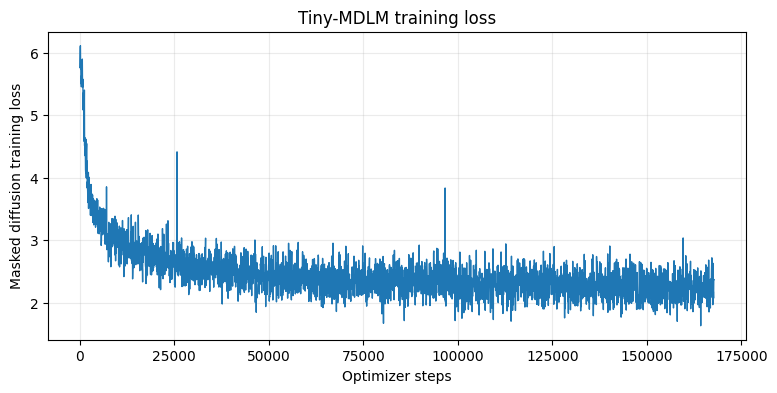

In [ ]:
if loss_history:
    steps, losses = zip(*loss_history)
    plt.figure(figsize=(9, 4))
    plt.plot(steps, losses, linewidth=1)
    plt.xlabel("Optimizer steps")
    plt.ylabel("Masked diffusion training loss")
    plt.title("Tiny-MDLM training loss")
    plt.grid(alpha=0.25)
    plt.show()
else:
    print("No logs yet. Run training for longer or lower LOG_EVERY.")

### Q2 Training summary

In [ ]:
import pandas as pd
from IPython.display import display

TABLE_DIR = OUTPUT_DIR / "tables"
TABLE_DIR.mkdir(parents=True, exist_ok=True)


@torch.inference_mode()
def evaluate_mdlm_objective(blocks, batch_size=64, seed=42):
    model.eval()
    cpu_state, cuda_state = torch.get_rng_state(), torch.cuda.get_rng_state()
    torch.manual_seed(seed)
    total, count = 0.0, 0
    for start in range(0, len(blocks), batch_size):
        clean = blocks[start:start + batch_size].to(DEVICE)
        with torch.autocast("cuda", dtype=torch.float16):
            loss = compute_mdlm_loss(model, clean)
        total += float(loss) * clean.size(0)
        count += clean.size(0)
    torch.set_rng_state(cpu_state)
    torch.cuda.set_rng_state(cuda_state)
    return total / count


valid_objective = evaluate_mdlm_objective(valid_ids)
train_objective = evaluate_mdlm_objective(train_ids[:len(valid_ids)])
recent_train = np.mean([loss for _, loss in loss_history[-20:]])
training_summary = pd.DataFrame(
    {"Value": [f"{n_params:,} ({n_params / 1e6:.2f}M)",
               f"{global_step:,} (batch {BATCH_SIZE}, {global_step * BATCH_SIZE / len(train_ids):.2f} epochs)",
               f"{elapsed / 60:.1f} min on {torch.cuda.get_device_name(0)}",
               f"{recent_train:.4f}",
               f"{train_objective:.4f}",
               f"{valid_objective:.4f}"]},
    index=pd.Index(["Parameters", "Optimizer steps", "GPU training time", "Train loss (last 1k steps, logged)",
                    "MDLM objective, train subset", "MDLM objective, validation"], name="Item"))
training_summary.to_csv(TABLE_DIR / "q2_training_summary.csv")
display(training_summary)


,Value
Item,
Parameters,"13,768,704 (13.77M)"
Optimizer steps,"167,760 (batch 64, 39.85 epochs)"
GPU training time,200.0 min on Tesla T4
"Train loss (last 1k steps, logged)",2.3128
"MDLM objective, train subset",2.2186
"MDLM objective, validation",2.2337


## 11. Validation


In [ ]:
@torch.inference_mode()
def evaluate_masked(mask_ratio=0.5, max_blocks=512, batch_size=16, seed=42):
    """Fixed-ratio reconstruction metrics on held-out validation blocks.

    Masked CE is cross entropy averaged over masked valid tokens.
    It is not standard autoregressive perplexity.
    """
    model.eval()
    subset = valid_ids[:max_blocks]
    rng = torch.Generator(device=DEVICE)
    rng.manual_seed(seed)

    total_ce = 0.0
    correct = 0
    count = 0

    for start in range(0, len(subset), batch_size):
        clean = subset[start:start + batch_size].to(DEVICE)
        valid = clean.ne(PAD)
        mask = (
            torch.rand(clean.shape, device=DEVICE, generator=rng) < mask_ratio
        ) & valid
        if not mask.any().item():
            continue

        noisy = clean.masked_fill(mask, MASK)
        with torch.autocast("cuda", dtype=torch.float16):
            logits = model(noisy)

        masked_logits = logits[mask].float()
        targets = clean[mask]
        total_ce += F.cross_entropy(
            masked_logits, targets, reduction="sum"
        ).item()
        correct += (masked_logits.argmax(dim=-1) == targets).sum().item()
        count += targets.numel()

    return total_ce / max(1, count), correct / max(1, count)


for ratio in (0.25, 0.50, 0.75):
    mce, acc = evaluate_masked(mask_ratio=ratio)
    print(f"Mask ratio {ratio:>3.0%}: Masked CE {mce:.4f} | Accuracy {acc:.2%}")


Mask ratio 25%: Masked CE 0.8832 | Accuracy 78.51%
Mask ratio 50%: Masked CE 1.5071 | Accuracy 65.75%
Mask ratio 75%: Masked CE 2.8023 | Accuracy 42.50%


### Q3(a) Masked cross-entropy on the full held-out validation set

Validation blocks: 2061


Mask ratio,Masked CE,Masked token accuracy
25%,1.0666,74.27%
50%,1.7473,61.11%
75%,3.0707,38.91%


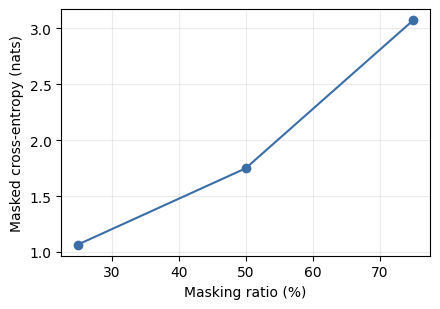

In [ ]:
import pandas as pd
from IPython.display import display

mce_rows = []
for ratio in (0.25, 0.50, 0.75):
    mce, acc = evaluate_masked(mask_ratio=ratio, max_blocks=len(valid_ids))
    mce_rows.append({"Mask ratio": ratio, "Masked CE": mce, "Masked token accuracy": acc})
mce_table = pd.DataFrame(mce_rows)
print(f"Validation blocks: {len(valid_ids)}")
mce_table.to_csv(TABLE_DIR / "q3a_masked_ce.csv", index=False)
display(mce_table.style.format({"Mask ratio": "{:.0%}", "Masked CE": "{:.4f}", "Masked token accuracy": "{:.2%}"})
        .hide(axis="index"))
fig, ax = plt.subplots(figsize=(4.5, 3.2))
ax.plot(mce_table["Mask ratio"] * 100, mce_table["Masked CE"], marker="o", color="#3b6ea5")
ax.set_xlabel("Masking ratio (%)")
ax.set_ylabel("Masked cross-entropy (nats)")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "mce_vs_ratio.png", dpi=300)
plt.show()


## 12. MDLM Iterative Generation（Confidence-based）


**HW2 Q1(c) TODO:** Complete `iterative_decode()` in the cell below.
The provided `generate()` wrapper prepares the prompt and converts tokens back to text.


In [ ]:
# ==============================================================
# HW2 Problem 2 - Question 1(c): Iterative Decoding (8%)
# ==============================================================
@torch.inference_mode()
def iterative_decode(model, x, steps=16, show_trace=True):
    """Fill a masked suffix while preserving the prompt/fixed tokens."""

    for s in range(steps):
        with torch.autocast("cuda", dtype=torch.float16):
            logits = model(x)
        logits = logits.float()
        logits[..., [PAD, MASK, UNK]] = -1e9

        # TODO 1(c) - Part A:
        # Obtain a predicted token and its confidence at each position.
        #
        # ---------------- STUDENT CODE START ---------------------
        probs = logits.softmax(dim=-1)
        confidence, predicted = probs.max(dim=-1)
        # ----------------- STUDENT CODE END ----------------------

        remaining = x.eq(MASK)
        n_remaining = int(remaining.sum().item())
        if n_remaining == 0:
            break

        k = math.ceil(n_remaining / (steps - s))

        # TODO 1(c) - Part B:
        # - Only rank positions that are STILL masked.
        # - Choose the k positions with the highest confidence.
        # - Reveal their predicted token IDs in x.
        # - Never change prompt tokens or previously revealed tokens.
        #
        # ---------------- STUDENT CODE START ---------------------
        confidence = confidence.masked_fill(~remaining, -1.0)
        top = confidence.topk(k, dim=-1).indices
        reveal = torch.zeros_like(remaining).scatter_(1, top, True) & remaining
        x = torch.where(reveal, predicted, x)
        # ----------------- STUDENT CODE END ----------------------

        if show_trace and (s == 0 or (s + 1) % 4 == 0 or s + 1 == steps):
            print(
                f"Step {s+1:2d}:",
                tok.decode(x[0].tolist(), skip_special_tokens=False)[:350]
            )

    return x


# The prompt preparation, stopping condition, and text conversion
# are provided, so students only implement iterative_decode().
@torch.inference_mode()
def generate(prompt="Once upon a time", total_length=64, steps=16, show_trace=True):
    model.eval()
    prefix = tok.encode(prompt).ids
    if not (0 < len(prefix) < total_length <= SEQ_LEN):
        raise ValueError("Need 0 < prompt tokens < total_length <= SEQ_LEN")
    if not (1 <= steps <= total_length - len(prefix)):
        raise ValueError("steps must be between 1 and number of masked positions")

    x = torch.full((1, total_length), MASK, dtype=torch.long, device=DEVICE)
    x[0, :len(prefix)] = torch.tensor(prefix, dtype=torch.long, device=DEVICE)

    if show_trace:
        print("Initial:", tok.decode(x[0].tolist(), skip_special_tokens=False)[:350])

    x = iterative_decode(model, x, steps=steps, show_trace=show_trace)

    ids = x[0].tolist()
    if EOS in ids:
        ids = ids[:ids.index(EOS)]
    return tok.decode(ids, skip_special_tokens=True)


print("\n=== Final Generated Text ===")
print(generate("Once upon a time", total_length=64, steps=16))



=== Final Generated Text ===
Initial: Once upon a time[MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MAS
Step  1: Once upon a time, there[MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MA
Step  4: Once upon a time, there was a big[MASK].[MASK]. The was to[MASK][MASK][MASK][MASK][MASK].[MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][MASK][M

## 13. Conparsion between Decoding Steps


In [ ]:
for num_steps in (4, 8, 16):
    print(f"\n--- {num_steps} steps ---")
    print(generate("Once upon a time", total_length=64, steps=num_steps, show_trace=False))


--- 4 steps ---
Once upon a time, there was a big day... The was to very fast.. The day, the went........ The car went went fast........ The went went fast.... the home. Everyone happy. The end.

--- 8 steps ---
Once upon a time, there was a big seed. The was used to and grow.... The day, the seed started to grow... The flower was was big and strong... The seed was happy.. The seed was happy too.. It was was happy. The end.

--- 16 steps ---
Once upon a time, there was a big bird. The. The was to fly high in the sky. One day, the bird wanted to take a walk. The bird went to the park and saw a bird. The bird was happy to see the bird. It flew back to its home. The end.


### Q3(b) Timed generation with 4, 8 and 16 decoding steps

In [ ]:
import pandas as pd
from IPython.display import display


def distinct_ratio(text, n=2):
    words = text.split()
    grams = [tuple(words[i:i + n]) for i in range(len(words) - n + 1)]
    return len(set(grams)) / max(1, len(grams))


torch.manual_seed(SEED)
generation_rows = []
for num_steps in (4, 8, 16):
    generate("Once upon a time", total_length=64, steps=num_steps, show_trace=False)
    torch.cuda.synchronize()
    started_decode = time.perf_counter()
    text = generate("Once upon a time", total_length=64, steps=num_steps, show_trace=False)
    torch.cuda.synchronize()
    seconds = time.perf_counter() - started_decode
    generation_rows.append({"Steps": num_steps, "Time (ms)": seconds * 1000,
                            "distinct-2": distinct_ratio(text), "Text": text})
    print(f"\n--- {num_steps} steps | {seconds * 1000:.1f} ms | distinct-2 {distinct_ratio(text):.2f} ---")
    print(text)
generation_table = pd.DataFrame(generation_rows)
generation_table.to_csv(TABLE_DIR / "q3b_generation.csv", index=False)
display(generation_table.drop(columns="Text").style.format({"Time (ms)": "{:.1f}", "distinct-2": "{:.2f}"}).hide(axis="index"))



--- 4 steps | 15.3 ms | distinct-2 0.97 ---
Once upon a time, there was a big day... The was to very fast.. The day, the went........ The car went went fast........ The went went fast.... the home. Everyone happy. The end.

--- 8 steps | 36.5 ms | distinct-2 0.93 ---
Once upon a time, there was a big seed. The was used to and grow.... The day, the seed started to grow... The flower was was big and strong... The seed was happy.. The seed was happy too.. It was was happy. The end.

--- 16 steps | 61.2 ms | distinct-2 0.98 ---
Once upon a time, there was a big bird. The. The was to fly high in the sky. One day, the bird wanted to take a walk. The bird went to the park and saw a bird. The bird was happy to see the bird. It flew back to its home. The end.


Steps,Time (ms),distinct-2
4,15.3,0.97
8,36.5,0.93
16,61.2,0.98


## 14.


In [ ]:
# 選用：如要從先前保存的 checkpoint 恢復，設 True，再執行這格。
RESTORE_CHECKPOINT = False
if RESTORE_CHECKPOINT:
    assert CHECKPOINT_PATH.exists(), f"Cannot find {CHECKPOINT_PATH}"
    checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
    model.load_state_dict(checkpoint["model"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    scaler.load_state_dict(checkpoint["scaler"])
    global_step = checkpoint["step"]
    loss_history = checkpoint.get("loss_history", [])
    print("Restored at step", global_step)
else:
    print("Restore disabled (normal first run).")

Restore disabled (normal first run).


## 15. Report

**Setup**
- Seed 42, one Tesla T4 on Google Colab, PyTorch 2.11.0+cu130 (Colab default), FP16 with autocast and GradScaler.
- Data: first 120,000 training stories and 1,000 validation stories, packed into 128-token blocks without mixing stories (269,460 train blocks, 2,061 validation blocks).
- Tokenizer: the provided 8K BPE, trained on the first 20,000 training stories.
- Model: the provided Transformer (6 layers, hidden 384, 6 heads), random initialization.
- Changed settings:
  - TRAIN_STORIES 300,000 to 120,000, as required by the PDF.
  - BATCH_SIZE 4 to 64, because batch 4 is too noisy for a 14M model.
  - TRAIN_MINUTES 240 to 200, so the whole notebook (data loading, tokenizer, training and evaluation) stays inside the 4-hour T4 budget.
- Unchanged: AdamW (lr 2e-4, weight decay 0.05), gradient clipping, training loop.

### Q1 Implementation

The three functions follow the formulas in the PDF directly: mask each real token with probability t, weight the masked cross-entropy by 1/(tL), and reveal the most confident masked tokens step by step.

**(a) `forward_masking`**
- t per sequence from U(0, 1), clamped to at least 0.01, or fixed by `mask_ratio`.
- A token is masked if a uniform draw is below t and the token is not `[PAD]`.
- Masked tokens become `[MASK]`. Returns `(x_t, mask, t)` with a Boolean mask.
- Examples: 29%, 40%, 63% of 83 tokens masked for t = 0.25, 0.50, 0.75.
- Check: no PAD position is masked even at t = 0.99.

**(b) `compute_mdlm_loss`**
- Cross-entropy against the clean tokens, in FP32, kept only at masked positions.
- Summed per sequence, divided by `t * L` (L = non-PAD tokens), then averaged over the batch.
- Small t is safe: t is at least 0.01 (weight at most 100) and L is at least 1.

**(c) `iterative_decode`**
- Part A: softmax over the logits. Confidence is the max probability, the prediction is its token.
- Part B: non-masked positions get confidence -1, so the prompt and revealed tokens never change.
- `topk(k)` picks the k most confident masked positions and only those are filled.
- `k = ceil(n_remaining / (steps - s))` fills every mask by the last step.

### Q2 Training

The training loss went down steadily, and the validation loss stayed equal to the training loss, so the model did not overfit.

Table from `outputs/tables/q2_training_summary.csv`:


In [ ]:
import pandas as pd

pd.read_csv(OUTPUT_DIR / "tables" / "q2_training_summary.csv", index_col="Item")

,Value
Item,
Parameters,"13,768,704 (13.77M)"
Optimizer steps,"167,760 (batch 64, 39.85 epochs)"
GPU training time,200.0 min on Tesla T4
"Train loss (last 1k steps, logged)",2.3128
"MDLM objective, train subset",2.2186
"MDLM objective, validation",2.2337


- The loss decreases: 5.76 to about 3.0 in the first 10k steps, then slowly. The mean logged loss is 2.83 at steps 10k to 20k, 2.41 at 50k to 60k and 2.24 at 150k to 168k.
- The curve is noisy because each batch draws new t values and small t gets a large 1/t weight.
- No overfitting: validation loss (2.234) is almost equal to training loss on the same number of blocks (2.219), and training loss was still going down.
- 167,760 steps in 200 minutes (13.98 steps/s, about 39.8 epochs). The model is limited by compute, so longer training would likely still help.

### Q3 Evaluation and analysis

MCE grows quickly as more tokens are masked, and more decoding steps give more fluent text at a linear cost in time.

**(a) Masked cross-entropy** (all 2,061 validation blocks, fixed mask seed 42), from `outputs/tables/q3a_masked_ce.csv`:


In [ ]:
pd.read_csv(OUTPUT_DIR / "tables" / "q3a_masked_ce.csv").style.format(
    {"Mask ratio": "{:.0%}", "Masked CE": "{:.4f}", "Masked token accuracy": "{:.2%}"}).hide(axis="index")

Mask ratio,Masked CE,Masked token accuracy
25%,1.0666,74.27%
50%,1.7473,61.11%
75%,3.0707,38.91%


- MCE rises with the masking ratio. The jump from 50% to 75% (+1.32) is about twice the jump from 25% to 50% (+0.68).
- At 25% most neighbours are visible, so local grammar fills many tokens.
- At 75% the model sees only scattered words and must guess content words.

**(b) Generation** ("Once upon a time", 64 tokens, one sample after a warm-up, GPU synchronized), from `outputs/tables/q3b_generation.csv`:


In [ ]:
pd.read_csv(OUTPUT_DIR / "tables" / "q3b_generation.csv").drop(columns="Text").style.format(
    {"Time (ms)": "{:.1f}", "distinct-2": "{:.2f}"}).hide(axis="index")

Steps,Time (ms),distinct-2
4,15.3,0.97
8,36.5,0.93
16,61.2,0.98


- Speed: 15 ms, 37 ms and 61 ms for 4, 8 and 16 steps. Time grows linearly with steps, since each step is one full forward pass.
- Fluency: 4 and 8 steps break into fragments, doubled words ("went went", "was was") and stray periods. 16 steps gives a short, mostly grammatical story ("the bird wanted to take a walk ... It flew back to its home. The end.").
- Repetition: distinct-2 is 0.97, 0.93 and 0.98. The 8-step text repeats "The seed was happy", and even the 16-step text reuses "the bird" many times, because confidence-based decoding likes to copy a phrase that is already revealed.
- The 4-step and 8-step texts have many stray periods, because "." is high-confidence almost everywhere and gets revealed early. With 16 steps there are enough steps to fill words around it.

### Q4 Short answers

**(a) MDLM vs autoregressive generation**
- AR: one token per forward pass, left to right, each token sees only the prefix.
- MDLM: predicts all masked positions in parallel with a bidirectional model and reveals the most confident ones.
- MDLM needs as many passes as steps, not as tokens, and can fill tokens in any order.
- Downside: tokens revealed in the same step are chosen independently.

**(b) Why different masking ratios in training**
- Generation goes through every masking level, from almost fully masked to almost clean.
- Sampling t from U(0, 1) trains one model for all levels, and the 1/t weight makes the loss a likelihood bound.
- Low t teaches local grammar, high t teaches overall story structure.

**(c) Why low loss can still give repetitive or incoherent text**
- The loss scores each masked token independently and never checks if tokens from the same step fit together.
- Low MCE mostly reflects easy cases with many visible neighbours, but generation starts almost fully masked.
- Greedy confidence decoding favors frequent tokens like "." or a repeated name, and revealed tokens are never revised.
